# 02 — Modelling (cross-validation on training data only)
**Project:** Who should be referred for a glucose tolerance test? (see [`docs/problem_definition.md`](../docs/problem_definition.md))

**Rules for this stage**
- Only the **training split** (614 patients) is used. The test set stays untouched until notebook 03.
- Every comparison uses the **same 5-fold × 10-repeat stratified cross-validation** (50 train/validation splits),
  so models are compared on identical data (a *paired* comparison).
- All preprocessing (log transform, imputation, scaling) happens **inside** the pipelines (`src/models.py`), so each
  validation fold is treated like unseen data.

**Metrics** (fixed in the problem definition)
- **Sensitivity at the guideline's referral rate:** in each validation fold, the rule refers some share of patients.
  A model refers the *same number* of its highest-risk patients, and we measure what share of diabetes cases each one catches.
- **ROC-AUC** and **PR-AUC (average precision):** overall ranking quality.

In [1]:
import sys, json, platform
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import sklearn
from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedKFold, cross_val_predict
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss
from sklearn.calibration import calibration_curve

from src.data import load_clean, train_test, TARGET, NO_LAB_FEATURES, ALL_FEATURES, PROJECT_ROOT
from src.models import (GuidelineRule, logistic, random_forest, gradient_boosting,
                        sensitivity_at_rate, threshold_for_rate)

sns.set_theme(style="whitegrid")
train, _ = train_test(load_clean())   # the test split is discarded here on purpose
y = train[TARGET].reset_index(drop=True)
X = train.drop(columns=TARGET).reset_index(drop=True)
print("Training patients:", len(X), "  diabetes rate:", round(y.mean(), 3))

CV = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=42)
SPLITS = list(CV.split(X, y))
print("Number of train/validation splits:", len(SPLITS))

Training patients: 614   diabetes rate: 0.349
Number of train/validation splits: 50


## 1. The evaluation loop
For every split we record, per model, ROC-AUC, PR-AUC and sensitivity at the rule's referral rate in that fold.

In [2]:
def evaluate(name, make_model, features):
    rows = []
    for fold, (tr, va) in enumerate(SPLITS):
        X_tr, X_va, y_tr, y_va = X.iloc[tr], X.iloc[va], y.iloc[tr], y.iloc[va]
        rule_rate = GuidelineRule().predict(X_va).mean()          # same referral rate for every model
        model = make_model(features).fit(X_tr[features], y_tr)
        scores = model.predict_proba(X_va[features])[:, 1]
        rows.append({"model": name, "fold": fold,
                     "roc_auc": roc_auc_score(y_va, scores),
                     "pr_auc": average_precision_score(y_va, scores),
                     "sens_at_rule_rate": sensitivity_at_rate(y_va, scores, rule_rate)})
    return pd.DataFrame(rows)


def summary(results):
    return (results.groupby("model")[["sens_at_rule_rate", "roc_auc", "pr_auc"]]
            .agg(["mean", "std"]).round(3))


def paired_vs(results, baseline, metric):
    """Per-fold difference of each model against the baseline on the same folds."""
    wide = results.pivot(index="fold", columns="model", values=metric)
    diff = wide.drop(columns=baseline).sub(wide[baseline], axis=0)
    return pd.DataFrame({"mean diff": diff.mean(), "std": diff.std(),
                         "folds better": (diff > 0).mean()}).round(3).sort_values("mean diff", ascending=False)

## 2. Question 1: the no-lab model vs the guideline rule
Candidates, from simplest to most complex. Each one tests a decision recorded in the data audit.

In [3]:
no_lab_candidates = {
    "Guideline rule (Age≥35 & BMI≥25)": lambda f: GuidelineRule(),
    "LogReg (median impute)":           lambda f: logistic(f),
    "LogReg + log transform":           lambda f: logistic(f, log_transform=True),
    "LogReg + log + missing indicators": lambda f: logistic(f, log_transform=True, add_indicator=True),
    "LogReg + iterative impute":        lambda f: logistic(f, imputer="iterative"),
    "Random Forest":                    random_forest,
    "Gradient Boosting":                gradient_boosting,
}
no_lab = pd.concat([evaluate(n, m, NO_LAB_FEATURES) for n, m in no_lab_candidates.items()], ignore_index=True)
summary(no_lab).sort_values(("sens_at_rule_rate", "mean"), ascending=False)

sens_at_rule_rate        roc_auc         \
                                               mean    std    mean    std   
model                                                                       
LogReg + log transform                        0.522  0.060   0.754  0.030   
LogReg + log + missing indicators             0.520  0.063   0.753  0.032   
LogReg (median impute)                        0.519  0.058   0.753  0.030   
LogReg + iterative impute                     0.519  0.060   0.754  0.030   
Random Forest                                 0.512  0.069   0.744  0.038   
Guideline rule (Age≥35 & BMI≥25)              0.509  0.066   0.638  0.039   
Gradient Boosting                             0.500  0.068   0.730  0.043   

                                  pr_auc         
                                    mean    std  
model                                            
LogReg + log transform             0.605  0.050  
LogReg + log + missing indicators  0.599  0.050  
LogReg (median impute)             0.603  0.050  
LogReg + iterative impute          0.604  0.051  
Random Forest                      0.577  0.057  
Guideline rule (Age≥35 & BMI≥25)   0.449  0.037  
Gradient Boosting                  0.551  0.057

In [4]:
RULE = "Guideline rule (Age≥35 & BMI≥25)"
print("Sensitivity at the rule's referral rate — difference vs the rule, same folds:")
paired_vs(no_lab, RULE, "sens_at_rule_rate")

Sensitivity at the rule's referral rate — difference vs the rule, same folds:


,mean diff,std,folds better
model,,,
LogReg + log transform,0.012,0.052,0.48
LogReg (median impute),0.010,0.057,0.54
LogReg + log + missing indicators,0.010,0.050,0.44
LogReg + iterative impute,0.010,0.056,0.52
Random Forest,0.003,0.057,0.44
Gradient Boosting,-0.009,0.066,0.40


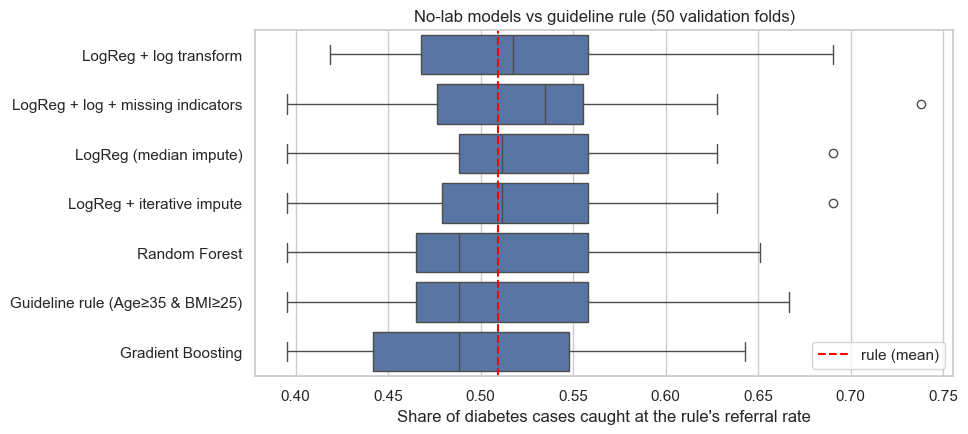

In [5]:
order = summary(no_lab).sort_values(("sens_at_rule_rate", "mean"), ascending=False).index
plt.figure(figsize=(9, 4.5))
sns.boxplot(data=no_lab, y="model", x="sens_at_rule_rate", order=order)
plt.axvline(no_lab.loc[no_lab.model == RULE, "sens_at_rule_rate"].mean(), color="red", linestyle="--", label="rule (mean)")
plt.xlabel("Share of diabetes cases caught at the rule's referral rate")
plt.ylabel("")
plt.title("No-lab models vs guideline rule (50 validation folds)")
plt.legend()
plt.show()

**What this shows**
- Every logistic-regression variant catches about **52 %** of cases at the rule's referral rate, while the rule catches **51 %**.
  The paired difference is only **+1.0 to +1.2 percentage points**, with a fold-to-fold standard deviation of about 5 points.
  The model does better in only **about half the folds**.
- **That's a tie, not a win.** On cross-validation, the no-lab model **does not meet the success criterion** set in the problem definition.
  The final verdict, with confidence intervals, comes from the test set in notebook 03, but there is little reason to expect a different answer.
- The models' ROC-AUC (≈ 0.75) is much higher than the rule's (≈ 0.64). That is mostly because a yes/no rule ranks patients badly
  everywhere except at its one cut-off. At the cut-off the rule actually uses, the two are equal.
- More complex models don't help: Random Forest ≈ the rule, and Gradient Boosting is slightly *worse*. With ~490 training patients per fold
  and weak features, flexible models mostly fit noise.
- The log transform, missing-value indicators and iterative imputation change nothing that matters (differences < 0.005), as the audit predicted.

### 2.1 Is the guideline just one lucky operating point?
A rule gives only **one** referral rate, while a model can refer any share of patients. So we also compare the model with
several other simple rules, each at **that rule's own** referral rate. The model used is the plain logistic regression.

In [6]:
simple_rules = {
    "BMI ≥ 25":            lambda d: d.BMI >= 25,
    "Age ≥ 35":            lambda d: d.Age >= 35,
    "Age ≥ 35 & BMI ≥ 25": lambda d: (d.Age >= 35) & (d.BMI >= 25),
    "Age ≥ 35 or BMI ≥ 30": lambda d: (d.Age >= 35) | (d.BMI >= 30),
    "Age ≥ 45 & BMI ≥ 30": lambda d: (d.Age >= 45) & (d.BMI >= 30),
}
rows = []
for fold, (tr, va) in enumerate(SPLITS):
    model = logistic(NO_LAB_FEATURES).fit(X.iloc[tr][NO_LAB_FEATURES], y.iloc[tr])
    scores = model.predict_proba(X.iloc[va][NO_LAB_FEATURES])[:, 1]
    y_va = y.iloc[va].to_numpy()
    for name, rule in simple_rules.items():
        referred = rule(X.iloc[va]).to_numpy()
        rows.append({"rule": name, "referral rate": referred.mean(),
                     "rule catches": (referred & (y_va == 1)).sum() / y_va.sum(),
                     "model catches": sensitivity_at_rate(y_va, scores, referred.mean())})
rules_cmp = pd.DataFrame(rows)
rules_cmp["diff"] = rules_cmp["model catches"] - rules_cmp["rule catches"]
(rules_cmp.groupby("rule")
 .agg(**{"referral rate": ("referral rate", "mean"), "rule catches": ("rule catches", "mean"),
         "model catches": ("model catches", "mean"), "mean diff": ("diff", "mean"),
         "std diff": ("diff", "std"), "folds model better": ("diff", lambda d: (d > 0).mean())})
 .sort_values("referral rate").round(3))

,referral rate,rule catches,model catches,mean diff,std diff,folds model better
rule,,,,,,
Age ≥ 45 & BMI ≥ 30,0.098,0.182,0.188,0.006,0.037,0.44
Age ≥ 35 & BMI ≥ 25,0.329,0.509,0.519,0.010,0.057,0.54
Age ≥ 35,0.368,0.533,0.566,0.033,0.056,0.70
Age ≥ 35 or BMI ≥ 30,0.733,0.921,0.943,0.022,0.027,0.64
BMI ≥ 25,0.847,0.958,0.979,0.021,0.028,0.64


**What this shows**
- At **every** rule's own referral rate, the model catches **as many or slightly more** cases on average: **+0.6 to +3.3 points**.
  It is never worse on average.
- The gains are small and inconsistent. The model does better in **44–70 %** of folds. The clearest gain is against *Age ≥ 35 alone*
  (+3.3 points, better in 70 % of folds).
- **Honest interpretation:** the no-lab model behaves like *the best simple rule at whatever referral rate you choose*.
  Its practical value is **flexibility**: a clinic can set the referral rate to match its testing capacity. It is not
  more accurate than a well-chosen rule. A clinic that only ever refers ~33 % of patients gains almost nothing from it.

## 3. Question 2: the full model (with lab values) vs glucose alone
The baseline is a logistic regression on **Glucose only**. Its ranking is the same as ranking patients by their glucose value.

In [7]:
full_candidates = {
    "Glucose only":                  lambda f: logistic(["Glucose"]),
    "LogReg (median impute)":        lambda f: logistic(f),
    "LogReg + log transform":        lambda f: logistic(f, log_transform=True),
    "LogReg + log + missing indicators": lambda f: logistic(f, log_transform=True, add_indicator=True),
    "Random Forest":                 random_forest,
    "Gradient Boosting":             gradient_boosting,
}
full = pd.concat([evaluate(n, m, ALL_FEATURES if n != "Glucose only" else ["Glucose"])
                  for n, m in full_candidates.items()], ignore_index=True)
summary(full).sort_values(("roc_auc", "mean"), ascending=False)

sens_at_rule_rate        roc_auc         \
                                               mean    std    mean    std   
model                                                                       
LogReg + log transform                        0.654  0.065   0.842  0.029   
LogReg (median impute)                        0.646  0.061   0.840  0.030   
LogReg + log + missing indicators             0.644  0.066   0.838  0.032   
Random Forest                                 0.632  0.067   0.833  0.033   
Gradient Boosting                             0.620  0.066   0.816  0.035   
Glucose only                                  0.609  0.058   0.798  0.036   

                                  pr_auc         
                                    mean    std  
model                                            
LogReg + log transform             0.738  0.058  
LogReg (median impute)             0.735  0.058  
LogReg + log + missing indicators  0.736  0.057  
Random Forest                      0.721  0.058  
Gradient Boosting                  0.702  0.058  
Glucose only                       0.707  0.049

In [8]:
print("ROC-AUC — difference vs Glucose only, same folds:")
paired_vs(full, "Glucose only", "roc_auc")

ROC-AUC — difference vs Glucose only, same folds:


,mean diff,std,folds better
model,,,
LogReg + log transform,0.044,0.022,0.98
LogReg (median impute),0.042,0.021,0.98
LogReg + log + missing indicators,0.040,0.027,0.90
Random Forest,0.035,0.033,0.82
Gradient Boosting,0.018,0.033,0.72


**What this shows**
- **Every** full model beats glucose alone. The chosen logistic regression adds about **+0.04 ROC-AUC** and is better in **98 % of folds**.
  At the rule's referral rate, it catches about **65 %** of cases vs **61 %** for glucose alone.
- That is a consistent improvement, so the full model is **likely to meet its success criterion**. Notebook 03 checks this formally with a confidence interval on the test set.
- Again, the simple linear model beats Random Forest and Gradient Boosting.

## 4. Model selection
**Rule:** among models whose mean score is within one standard error of the best, pick the **simplest**.
On a small dataset, a complex model that wins by a hair has usually just got lucky on these particular splits.

In [9]:
def one_se_choice(results, metric, simplicity_order):
    stats = results.groupby("model")[metric].agg(["mean", "std", "count"])
    stats["se"] = stats["std"] / np.sqrt(stats["count"])
    best = stats["mean"].idxmax()
    ok = stats.index[stats["mean"] >= stats.loc[best, "mean"] - stats.loc[best, "se"]]
    choice = next(m for m in simplicity_order if m in ok)
    return best, list(ok), choice

simplicity = ["LogReg (median impute)", "LogReg + log transform", "LogReg + log + missing indicators",
              "LogReg + iterative impute", "Random Forest", "Gradient Boosting"]
chosen = {}
for key, res, metric in [("no_lab", no_lab[no_lab.model != RULE], "sens_at_rule_rate"),
                         ("full", full[full.model != "Glucose only"], "roc_auc")]:
    best, ok, choice = one_se_choice(res, metric, simplicity)
    chosen[key] = choice
    print(f"{key:7s} best by mean: {best:35s} within 1 SE: {ok}\n        -> chosen: {choice}\n")

# Everything below uses the chosen configuration (looked up by name, not retyped)
FACTORIES = {"no_lab": no_lab_candidates, "full": full_candidates}
FEATURES = {"no_lab": NO_LAB_FEATURES, "full": ALL_FEATURES}
make_chosen = {key: FACTORIES[key][chosen[key]] for key in chosen}

no_lab  best by mean: LogReg + log transform              within 1 SE: ['LogReg (median impute)', 'LogReg + iterative impute', 'LogReg + log + missing indicators', 'LogReg + log transform']
        -> chosen: LogReg (median impute)

full    best by mean: LogReg + log transform              within 1 SE: ['LogReg (median impute)', 'LogReg + log transform']
        -> chosen: LogReg (median impute)



Both questions select the **plain logistic regression with median imputation**. The log-transform version has a marginally
higher mean, but the difference is well within one standard error, so the simpler model wins. This *overrides* the audit's suggestion
to log-transform skewed features: we tried it, and the data says it isn't needed. That's a decision **made from evidence, not habit**.

### 4.1 Tuning the regularisation strength
Logistic regression has one main setting, `C` (smaller means a simpler model). We check a few values on the same folds.
*Note:* choosing `C` on these folds makes the CV score slightly optimistic. The untouched test set in notebook 03 corrects for that.

In [10]:
assert all(name.startswith("LogReg") for name in chosen.values()), "tuning below assumes logistic regression"
tuning = []
for C in [0.01, 0.1, 1.0, 10.0]:
    for key in chosen:
        r = evaluate(f"{key} C={C}", lambda f, C=C: logistic(f, C=C), FEATURES[key])
        tuning.append(r.assign(set=key, C=C))
tuning = pd.concat(tuning)
tuning.groupby(["set", "C"])[["sens_at_rule_rate", "roc_auc"]].mean().round(3)

sens_at_rule_rate  roc_auc
set    C                                
full   0.01               0.641    0.840
       0.10               0.645    0.841
       1.00               0.646    0.840
       10.00              0.647    0.840
no_lab 0.01               0.521    0.752
       0.10               0.516    0.754
       1.00               0.519    0.753
       10.00              0.519    0.753

`C` makes practically no difference between 0.01 and 10 (all changes ≤ 0.006). With only 6–8 features and ~600 patients,
overfitting is not the problem here, so we **keep the default `C = 1`**. This also means our cross-validation scores are barely inflated by tuning.

## 5. Question 3: how much does the lab test add?
The chosen no-lab and full models compared on the same folds, with the guideline rule for reference.

In [11]:
lab_value = pd.DataFrame({
    f"no-lab ({chosen['no_lab']})": no_lab.query("model == @chosen['no_lab']")[["roc_auc", "pr_auc", "sens_at_rule_rate"]].mean(),
    f"full ({chosen['full']})":     full.query("model == @chosen['full']")[["roc_auc", "pr_auc", "sens_at_rule_rate"]].mean(),
    "guideline rule":               no_lab.query("model == @RULE")[["roc_auc", "pr_auc", "sens_at_rule_rate"]].mean(),
}).T.round(3)
lab_value

,roc_auc,pr_auc,sens_at_rule_rate
no-lab (LogReg (median impute)),0.753,0.603,0.519
full (LogReg (median impute)),0.840,0.735,0.646
guideline rule,0.638,0.449,0.509


**This is the most important result of the stage.**
- Adding the two lab values (glucose, insulin) raises the share of cases caught at the same referral rate from **52 % to 65 %**
  (about +13 points), and ROC-AUC from **0.75 to 0.84**.
- That gain is **more than ten times** what any modelling choice achieved on the no-lab features.
- **Implication for the screening question:** quick measurements can help decide *who to test*, but they can't replace the test.
  Information matters far more than algorithm choice here.

## 6. Are the predicted probabilities trustworthy? (calibration)
The app will show a **risk percentage**, so a predicted 30 % should mean that about 30 % of such patients have diabetes.
We compare our models with a version trained with `class_weight="balanced"`, a common trick for imbalanced data, using
out-of-fold predictions.

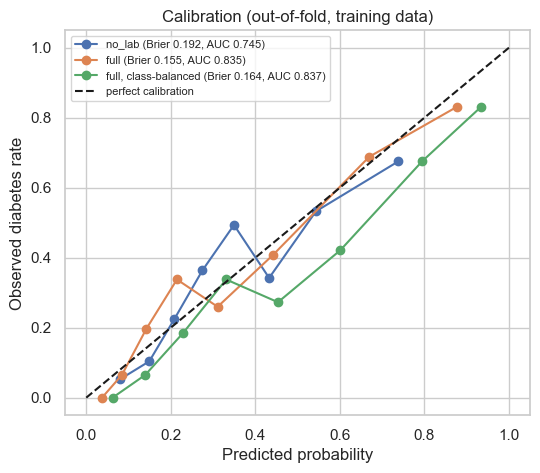

In [12]:
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
calib_models = {
    "no_lab":                (make_chosen["no_lab"](NO_LAB_FEATURES), NO_LAB_FEATURES),
    "full":                  (make_chosen["full"](ALL_FEATURES), ALL_FEATURES),
    "full, class-balanced":  (logistic(ALL_FEATURES, class_weight="balanced"), ALL_FEATURES),
}
oof = {name: cross_val_predict(m, X[f], y, cv=cv5, method="predict_proba")[:, 1] for name, (m, f) in calib_models.items()}

fig, ax = plt.subplots(figsize=(6, 5))
for name, p in oof.items():
    frac_pos, mean_pred = calibration_curve(y, p, n_bins=8, strategy="quantile")
    ax.plot(mean_pred, frac_pos, "o-", label=f"{name} (Brier {brier_score_loss(y, p):.3f}, AUC {roc_auc_score(y, p):.3f})")
ax.plot([0, 1], [0, 1], "k--", label="perfect calibration")
ax.set_xlabel("Predicted probability")
ax.set_ylabel("Observed diabetes rate")
ax.set_title("Calibration (out-of-fold, training data)")
ax.legend(fontsize=8)
plt.show()

- The two chosen models follow the diagonal reasonably well. The zig-zags come from having only ~75 patients per bin.
- The **class-balanced** model has practically the same AUC (0.837 vs 0.835) but sits **below the diagonal**: it **overestimates risk**.
  For example, where it predicts about 60 %, only about 40 % actually have diabetes. Its Brier score is also worse (0.164 vs 0.155; lower is better).
- **Decision confirmed:** no class weighting. Our main metrics are rank-based and the referral threshold is chosen explicitly,
  so weighting gains nothing and would make the app show inflated risk percentages.
- *Note:* the AUCs here come from a single 5-fold split, so they differ slightly from the 50-fold averages above. That's normal variation.

## 7. Operating thresholds
The app has to turn a probability into a referral suggestion. We set the threshold on **out-of-fold training predictions**:
- **Matched-rate threshold:** refers the same share of patients as the guideline rule (the primary comparison).
- **High-sensitivity threshold:** the highest cut-off that still catches at least 80 % of cases in training, for settings where missing cases is costlier.

In [13]:
rule_rate = GuidelineRule().predict(X).mean()

def high_sens_threshold(y_true, p, target=0.80):
    for t in np.sort(np.unique(p))[::-1]:
        if ((p >= t) & (y_true == 1)).sum() / y_true.sum() >= target:
            return float(t)

thresholds = {}
for key in chosen:
    p = oof[key]
    t_rate, t_sens = threshold_for_rate(p, rule_rate), high_sens_threshold(y.to_numpy(), p)
    thresholds[key] = {"matched_rate": t_rate, "high_sensitivity": t_sens}
    for label, t in [("matched rate", t_rate), ("high sensitivity", t_sens)]:
        ref = p >= t
        print(f"{key:7s} {label:17s} threshold {t:.3f}: refers {ref.mean():.1%}, "
              f"catches {(ref & (y == 1)).sum() / y.sum():.1%} of cases")
print(f"\nGuideline rule refers {rule_rate:.1%} of training patients.")

no_lab  matched rate      threshold 0.422: refers 32.9%, catches 50.5% of cases
no_lab  high sensitivity  threshold 0.283: refers 55.2%, catches 80.4% of cases
full    matched rate      threshold 0.418: refers 32.9%, catches 65.0% of cases
full    high sensitivity  threshold 0.250: refers 51.3%, catches 80.4% of cases

Guideline rule refers 32.9% of training patients.


## 8. Fit the chosen models on all training data and save them
These saved files are what notebook 03 evaluates on the test set and what the app will load.
Nothing about the test set has been used to build them.

In [14]:
models_dir = PROJECT_ROOT / "models"
models_dir.mkdir(exist_ok=True)
metadata = {"sklearn_version": sklearn.__version__, "python_version": platform.python_version(),
            "trained_on": "training split of src.data.train_test (seed 42), n=%d" % len(X),
            "guideline_rule_referral_rate_train": round(float(rule_rate), 4), "models": {}}
for key in chosen:
    feats = FEATURES[key]
    model = make_chosen[key](feats).fit(X[feats], y)
    joblib.dump(model, models_dir / f"{key}.joblib")
    cv_res = (no_lab if key == "no_lab" else full).query("model == @chosen[@key]")
    metadata["models"][key] = {
        "file": f"models/{key}.joblib", "features": feats, "config": chosen[key],
        "thresholds": {k: round(v, 4) for k, v in thresholds[key].items()},
        "cv_mean": cv_res[["roc_auc", "pr_auc", "sens_at_rule_rate"]].mean().round(4).to_dict(),
    }
(models_dir / "metadata.json").write_text(json.dumps(metadata, indent=2))
print(json.dumps(metadata, indent=2))

{
  "sklearn_version": "1.8.0",
  "python_version": "3.13.5",
  "trained_on": "training split of src.data.train_test (seed 42), n=614",
  "guideline_rule_referral_rate_train": 0.329,
  "models": {
    "no_lab": {
      "file": "models/no_lab.joblib",
      "features": [
        "Pregnancies",
        "BloodPressure",
        "SkinThickness",
        "BMI",
        "DiabetesPedigree",
        "Age"
      ],
      "config": "LogReg (median impute)",
      "thresholds": {
        "matched_rate": 0.4224,
        "high_sensitivity": 0.2835
      },
      "cv_mean": {
        "roc_auc": 0.7533,
        "pr_auc": 0.6031,
        "sens_at_rule_rate": 0.5194
      }
    },
    "full": {
      "file": "models/full.joblib",
      "features": [
        "Pregnancies",
        "BloodPressure",
        "SkinThickness",
        "BMI",
        "DiabetesPedigree",
        "Age",
        "Glucose",
        "Insulin"
      ],
      "config": "LogReg (median impute)",
      "thresholds": {
        "matched

In [15]:
coefs = pd.DataFrame({key: pd.Series(joblib.load(models_dir / f"{key}.joblib")[-1].coef_[0],
                                     index=joblib.load(models_dir / f"{key}.joblib")[:-1].get_feature_names_out())
                      for key in chosen}).round(2)
coefs.sort_values("full", key=abs, ascending=False)

,no_lab,full
Glucose,NaN,1.18
BMI,0.69,0.69
Pregnancies,0.30,0.38
DiabetesPedigree,0.28,0.23
Age,0.37,0.15
Insulin,NaN,-0.07
BloodPressure,0.07,-0.04
SkinThickness,0.11,0.03


Coefficients are per **one standard deviation** of each feature, so they can be compared with each other.
- **Glucose dominates** the full model (1.18), followed by **BMI** (0.69).
- **Age** shrinks from 0.37 to 0.15 once glucose is included. Part of age's effect seems to run *through* blood glucose.
- **Insulin** gets ≈ 0 (−0.07), even though on its own it looked strong in the audit (AUC ≈ 0.75). It adds nothing *beyond* glucose,
  because the two are correlated.
- Blood pressure and skinfold contribute almost nothing in either model.
- These are **associations, not causes**. Correlated features share credit in ways that can shift with small data changes.

## 9. Summary and plan for Stage 3
**Provisional answers (cross-validation on training data only)**

| Question | Result | Meets pre-set criterion? |
|---|---|---|
| 1. No-lab model vs guideline rule | Catches 52 % vs 51 % of cases at the same referral rate. Better in only about half of the folds. | **No (tie).** Its value is flexibility of referral rate, not accuracy. |
| 2. Full model vs glucose alone | ROC-AUC 0.84 vs 0.80. Better in 98 % of folds. | **Likely yes.** To be confirmed with a test-set CI. |
| 3. Value of the lab test | +13 points of cases caught at the same referral rate | (descriptive) |

**Decisions recorded**
- Model: plain logistic regression, median imputation, standard scaling, `C = 1`, no class weighting. Chosen by the one-SE rule over RF and GB.
- Rejected after testing: log transform, missing indicators, iterative imputation, class weighting.
- Saved to `models/`: `no_lab.joblib`, `full.joblib` and `metadata.json` with features, thresholds and CV scores.

**Plan for Stage 3 (notebook 03): the one and only look at the test set**
1. Evaluate both saved models and both baselines on the 154 test patients.
2. Compute **bootstrap 95 % confidence intervals** for the paired differences: no-lab vs rule (sensitivity at matched rate), full vs glucose (ROC-AUC).
3. Check calibration and the chosen thresholds on the test set.
4. Run error analysis (who is missed?) and a subgroup check by age group.
5. Write the final verdict for each research question, including the negative one.